# Ítem 2: Árboles de regresión con distintos hiperparámetros vs. Regresión Lineal (auto_mpg)

> **Enunciado:** Entrene modelos de árboles de decisión con varias configuraciones de hiper parámetros usando el dataset auto_mpg, comparar su eficiencia con respecto a un modelo lineal como el Regresor Lineal. ¿Cuál es el mejor?

## Objetivo y fundamento teórico

Un **árbol de regresión CART** particiona el espacio en regiones rectangulares $R_m$ y predice en cada hoja el
**promedio** de la variable objetivo. En cada nodo se elige el corte que más reduce el **MSE**:

$$I_{MSE}(\text{nodo}) = \frac{1}{N}\sum_{i \in \text{nodo}} (y_i - \bar{y}_{\text{nodo}})^2$$

La **Regresión Lineal** ajusta $\hat{y} = w^\top x + b$ minimizando la suma de errores al cuadrado.

El error de generalización se descompone en $\text{Sesgo}^2 + \text{Varianza} + \text{Error irreducible}$:
un árbol sin restricciones tiene **bajo sesgo y alta varianza** (sobreajuste), mientras que limitar
`max_depth` o aumentar `min_samples_leaf` reduce la varianza a costa de algo de sesgo.

**Objetivo:** predecir el consumo `mpg` (millas por galón) y comparar 5 configuraciones de árboles
(incluida una optimizada con `GridSearchCV`) frente a la Regresión Lineal, usando RMSE, MAE y $R^2$.

In [1]:
# ==============================================================================
# Configuración global, reproducibilidad y carga de utilidades comunes
# ==============================================================================
import json, os, sys, time, urllib.request, warnings

# Descargar ml_utils.py si no existe localmente
if not os.path.exists("ml_utils.py") and not os.path.exists("src/ml_utils.py"):
    url = "https://raw.githubusercontent.com/Edwardmamani/ML-UNAP-Tarea-Ejecucion-03/main/ml_utils.py"
    urllib.request.urlretrieve(url, "ml_utils.py")

for p in [".", "..", "src", "../src"]:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from ml_utils import (
    RANDOM_STATE,
    REPO_RAW,
    bootstrap_ci,
    load_csv,
    plot_roc,
    save_results,
    savefig,
    setup_environment,
)

setup_environment(RANDOM_STATE)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.1.0 | numpy 2.4.6


## 1. Carga y calidad de datos

In [2]:
df = load_csv("auto-mpg.csv")
df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")   # '?' -> NaN si existiera
print("Dimensiones:", df.shape)
print("\nNulos por columna:"); print(df.isna().sum()[df.isna().sum() > 0])
print("\nFilas duplicadas:", int(df.duplicated().sum()))
print("Valores de 'origin':", df["origin"].value_counts().to_dict())
display(df[df["horsepower"].isna()])
df.describe().T.round(2)

Dimensiones: (398, 9)

Nulos por columna:
horsepower    6
dtype: int64

Filas duplicadas: 0
Valores de 'origin': {'usa': 249, 'japan': 79, 'europe': 70}


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
32,25.0,4,98.0,NaN,2046,19.0,71,usa,ford pinto
126,21.0,6,200.0,NaN,2875,17.0,74,usa,ford maverick
330,40.9,4,85.0,NaN,1835,17.3,80,europe,renault lecar deluxe
336,23.6,4,140.0,NaN,2905,14.3,80,usa,ford mustang cobra
354,34.5,4,100.0,NaN,2320,15.8,81,europe,renault 18i
374,23.0,4,151.0,NaN,3035,20.5,82,usa,amc concord dl


,count,mean,std,min,25%,50%,75%,max
mpg,398.0,23.51,7.82,9.0,17.50,23.0,29.00,46.6
cylinders,398.0,5.45,1.70,3.0,4.00,4.0,8.00,8.0
displacement,398.0,193.43,104.27,68.0,104.25,148.5,262.00,455.0
horsepower,392.0,104.47,38.49,46.0,75.00,93.5,126.00,230.0
weight,398.0,2970.42,846.84,1613.0,2223.75,2803.5,3608.00,5140.0
acceleration,398.0,15.57,2.76,8.0,13.82,15.5,17.18,24.8
model_year,398.0,76.01,3.70,70.0,73.00,76.0,79.00,82.0


_(análisis pendiente)_

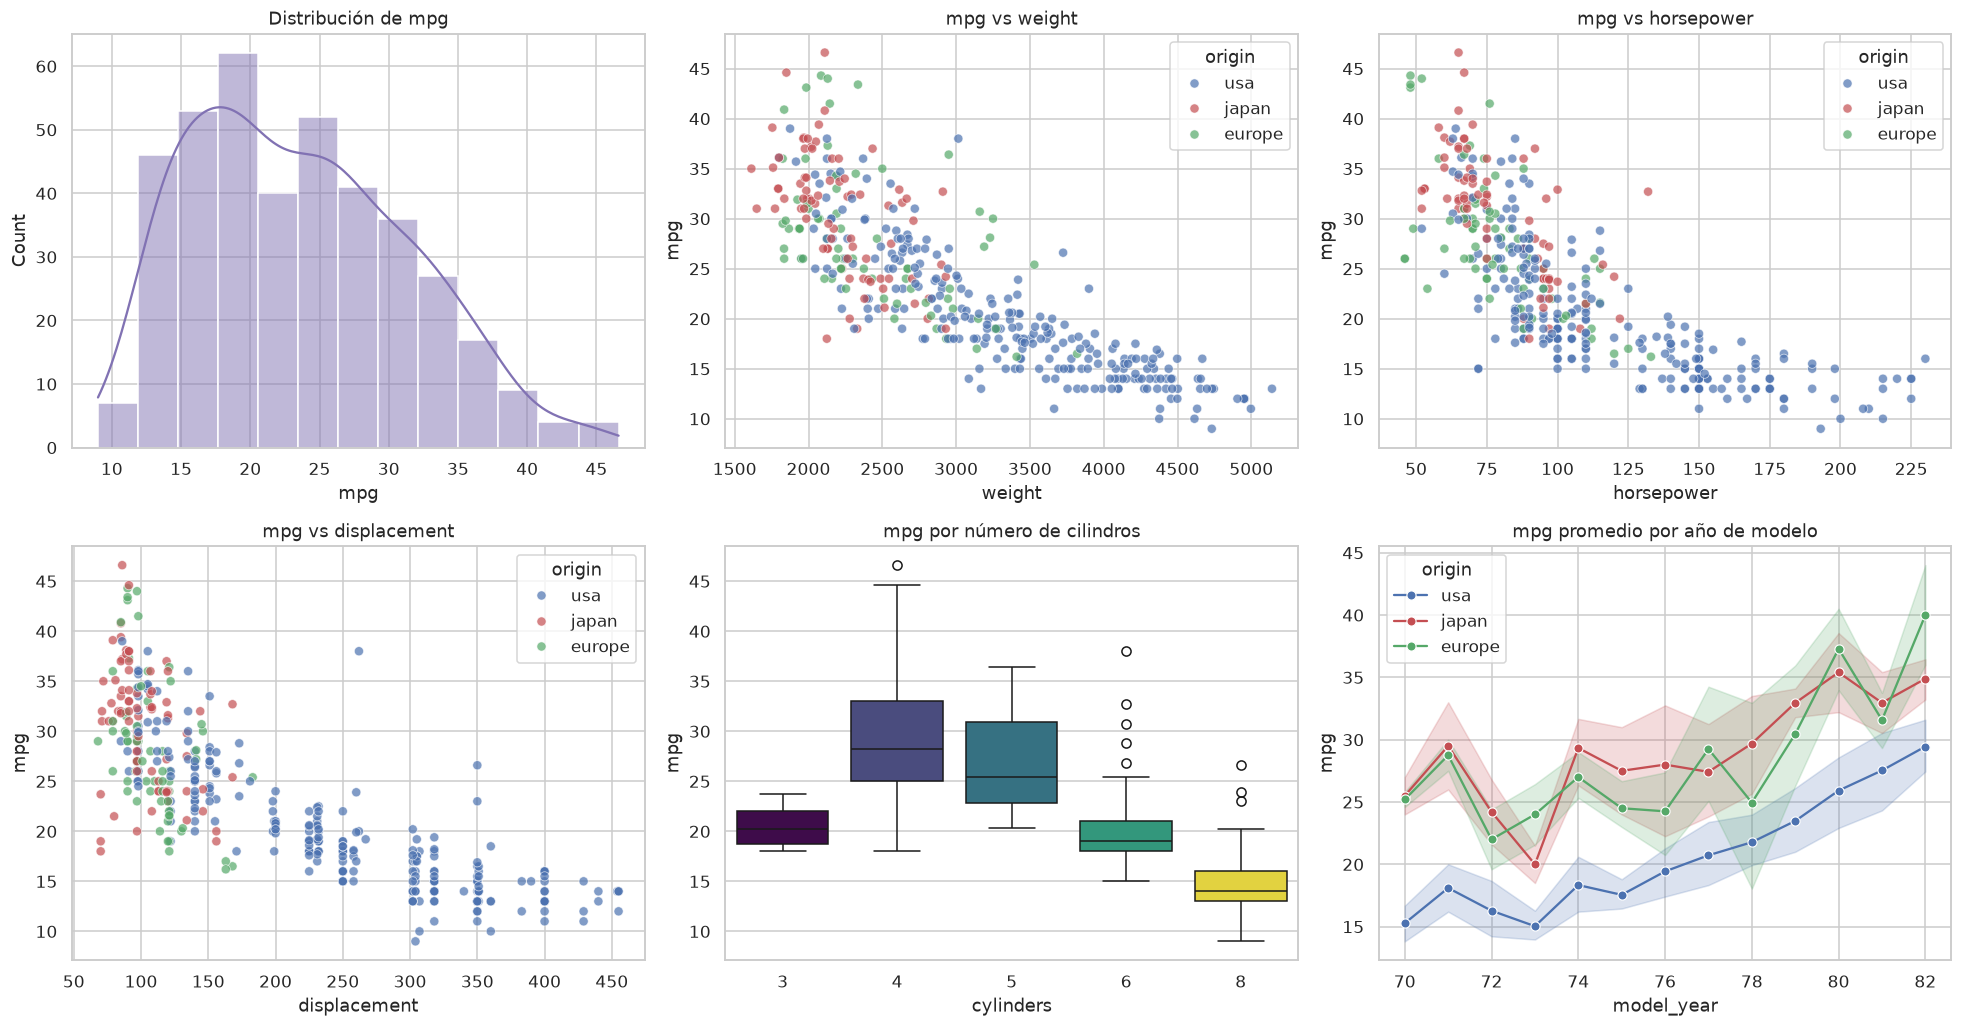

Correlación de Pearson con mpg:
 weight         -0.832
displacement   -0.804
horsepower     -0.778
cylinders      -0.775
acceleration    0.420
model_year      0.579
Name: mpg, dtype: float64


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9.5))
pal = {"usa": "#4C72B0", "japan": "#C44E52", "europe": "#55A868"}
sns.histplot(df["mpg"], kde=True, ax=axes[0, 0], color="#8172B3"); axes[0, 0].set_title("Distribución de mpg")
for ax, feat in zip([axes[0, 1], axes[0, 2], axes[1, 0]], ["weight", "horsepower", "displacement"]):
    sns.scatterplot(data=df, x=feat, y="mpg", hue="origin", palette=pal, alpha=0.7, ax=ax)
    ax.set_title(f"mpg vs {feat}")
sns.boxplot(data=df, x="cylinders", y="mpg", hue="cylinders", palette="viridis", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("mpg por número de cilindros")
sns.lineplot(data=df, x="model_year", y="mpg", hue="origin", palette=pal, marker="o", ax=axes[1, 2])
axes[1, 2].set_title("mpg promedio por año de modelo")
plt.tight_layout(); savefig("item2_eda"); plt.show()

corr = df.drop(columns=["name", "origin"]).corr(numeric_only=True)["mpg"].drop("mpg").sort_values()
print("Correlación de Pearson con mpg:\n", corr.round(3))

_(análisis pendiente)_

## 2. Partición y preprocesamiento (sin fuga de información)

In [4]:
from sklearn.model_selection import train_test_split, KFold

features_num = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
features_cat = ["origin"]
X = df[features_num + features_cat]
y = df["mpg"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Nulos de horsepower en train:", int(X_train['horsepower'].isna().sum()),
      "| en test:", int(X_test['horsepower'].isna().sum()))

Train: (318, 7) | Test: (80, 7)
Nulos de horsepower en train: 5 | en test: 1


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

def make_preprocessor(scale: bool):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), features_num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), features_cat),
    ])

* Se descarta `name` (identificador del vehículo con ~300 valores distintos: no generaliza y causaría sobreajuste).
* Los 6 valores faltantes de `horsepower` se **imputan con la mediana del conjunto de entrenamiento** dentro del
  `Pipeline` (se conservan las filas en lugar de eliminarlas).
* `origin` (nominal) se codifica con **One-Hot**. Solo la Regresión Lineal recibe `StandardScaler`
  (los árboles son invariantes a transformaciones monótonas de las variables).

## 3. Modelos: Regresión Lineal y 5 configuraciones de árboles

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

def tree(**kw):
    return Pipeline([("prep", make_preprocessor(False)),
                     ("model", DecisionTreeRegressor(random_state=RANDOM_STATE, **kw))])

models = {
    "Regresión Lineal": Pipeline([("prep", make_preprocessor(True)), ("model", LinearRegression())]),
    "CART-1 sin podar": tree(),
    "CART-2 max_depth=3": tree(max_depth=3),
    "CART-3 depth=5, leaf=5, split=10": tree(max_depth=5, min_samples_leaf=5, min_samples_split=10),
    "CART-4 depth=4, leaf=10%": tree(max_depth=4, min_samples_leaf=0.1),
}

kf = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
param_grid = {
    "model__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "model__min_samples_leaf": [1, 2, 4, 6, 8, 10, 15],
    "model__min_samples_split": [2, 10, 20],
    "model__criterion": ["squared_error", "friedman_mse", "absolute_error"],
}
grid = GridSearchCV(tree(), param_grid, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
grid.fit(X_train, y_train)
best_params = {k.replace("model__", ""): v for k, v in grid.best_params_.items()}
print("Combinaciones evaluadas:", len(grid.cv_results_["params"]))
print("Mejores hiperparámetros:", best_params, "| RMSE CV =", round(-grid.best_score_, 4))
models["CART-5 GridSearchCV"] = grid.best_estimator_

Combinaciones evaluadas: 504
Mejores hiperparámetros: {'criterion': 'squared_error', 'max_depth': 8, 'min_samples_leaf': 8, 'min_samples_split': 2} | RMSE CV = 3.1938


_(análisis pendiente)_

## 4. Evaluación: RMSE / MAE / R² en entrenamiento, validación cruzada 10-Fold y prueba

In [7]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

rows, cv_rmse, preds = [], {}, {}
for name, model in models.items():
    cvres = cross_validate(model, X_train, y_train, cv=kf, n_jobs=-1,
                           scoring=["neg_root_mean_squared_error", "r2"])
    model.fit(X_train, y_train)
    p_tr, p_te = model.predict(X_train), model.predict(X_test)
    preds[name] = p_te
    cv_rmse[name] = -cvres["test_neg_root_mean_squared_error"]
    est = model.named_steps["model"]
    rows.append({
        "Modelo": name,
        "RMSE train": rmse(y_train, p_tr),
        "RMSE CV (media)": cv_rmse[name].mean(),
        "RMSE CV (std)": cv_rmse[name].std(),
        "RMSE test": rmse(y_test, p_te),
        "MAE test": mean_absolute_error(y_test, p_te),
        "R² train": r2_score(y_train, p_tr),
        "R² CV": cvres["test_r2"].mean(),
        "R² test": r2_score(y_test, p_te),
        "Profundidad": est.get_depth() if hasattr(est, "get_depth") else np.nan,
        "Hojas": est.get_n_leaves() if hasattr(est, "get_n_leaves") else np.nan,
    })
results = pd.DataFrame(rows).set_index("Modelo")
results["CV/train (diagnóstico)"] = results["RMSE CV (media)"] / results["RMSE train"]
results.round(3)

,RMSE train,RMSE CV (media),RMSE CV (std),RMSE test,MAE test,R² train,R² CV,R² test,Profundidad,Hojas,CV/train (diagnóstico)
Modelo,,,,,,,,,,,
Regresión Lineal,3.370,3.451,0.533,2.888,2.288,0.819,0.796,0.845,NaN,NaN,1.024
CART-1 sin podar,0.000,3.798,0.949,3.368,2.271,1.000,0.756,0.789,18.0,261.0,inf
CART-2 max_depth=3,3.231,3.773,0.529,3.719,2.684,0.833,0.756,0.743,3.0,8.0,1.168
"CART-3 depth=5, leaf=5, split=10",2.385,3.343,0.634,2.709,2.032,0.909,0.810,0.863,5.0,27.0,1.402
"CART-4 depth=4, leaf=10%",3.420,3.815,0.589,3.321,2.611,0.813,0.753,0.795,3.0,7.0,1.116
CART-5 GridSearchCV,2.407,3.194,0.675,2.734,2.030,0.908,0.825,0.861,8.0,32.0,1.327


_(análisis pendiente)_

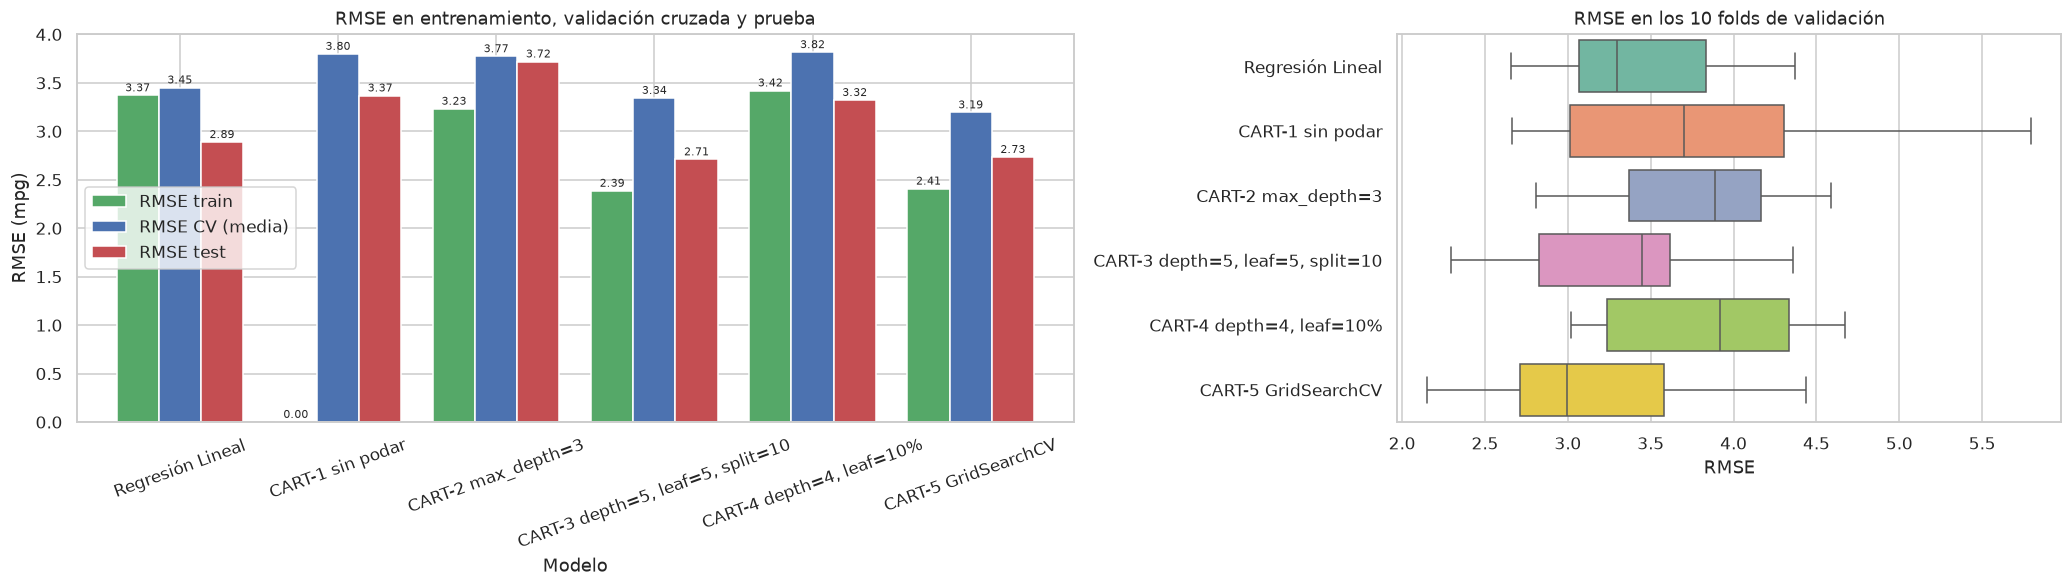

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
results[["RMSE train", "RMSE CV (media)", "RMSE test"]].plot(
    kind="bar", ax=axes[0], color=["#55A868", "#4C72B0", "#C44E52"], width=0.8)
axes[0].set_ylabel("RMSE (mpg)"); axes[0].set_title("RMSE en entrenamiento, validación cruzada y prueba")
axes[0].tick_params(axis="x", rotation=20)
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.2f", fontsize=7, padding=1)
cv_df = pd.DataFrame(cv_rmse).melt(var_name="Modelo", value_name="RMSE")
sns.boxplot(data=cv_df, y="Modelo", x="RMSE", hue="Modelo", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("RMSE en los 10 folds de validación"); axes[1].set_ylabel("")
plt.tight_layout(); savefig("item2_comparacion"); plt.show()

_(análisis pendiente)_

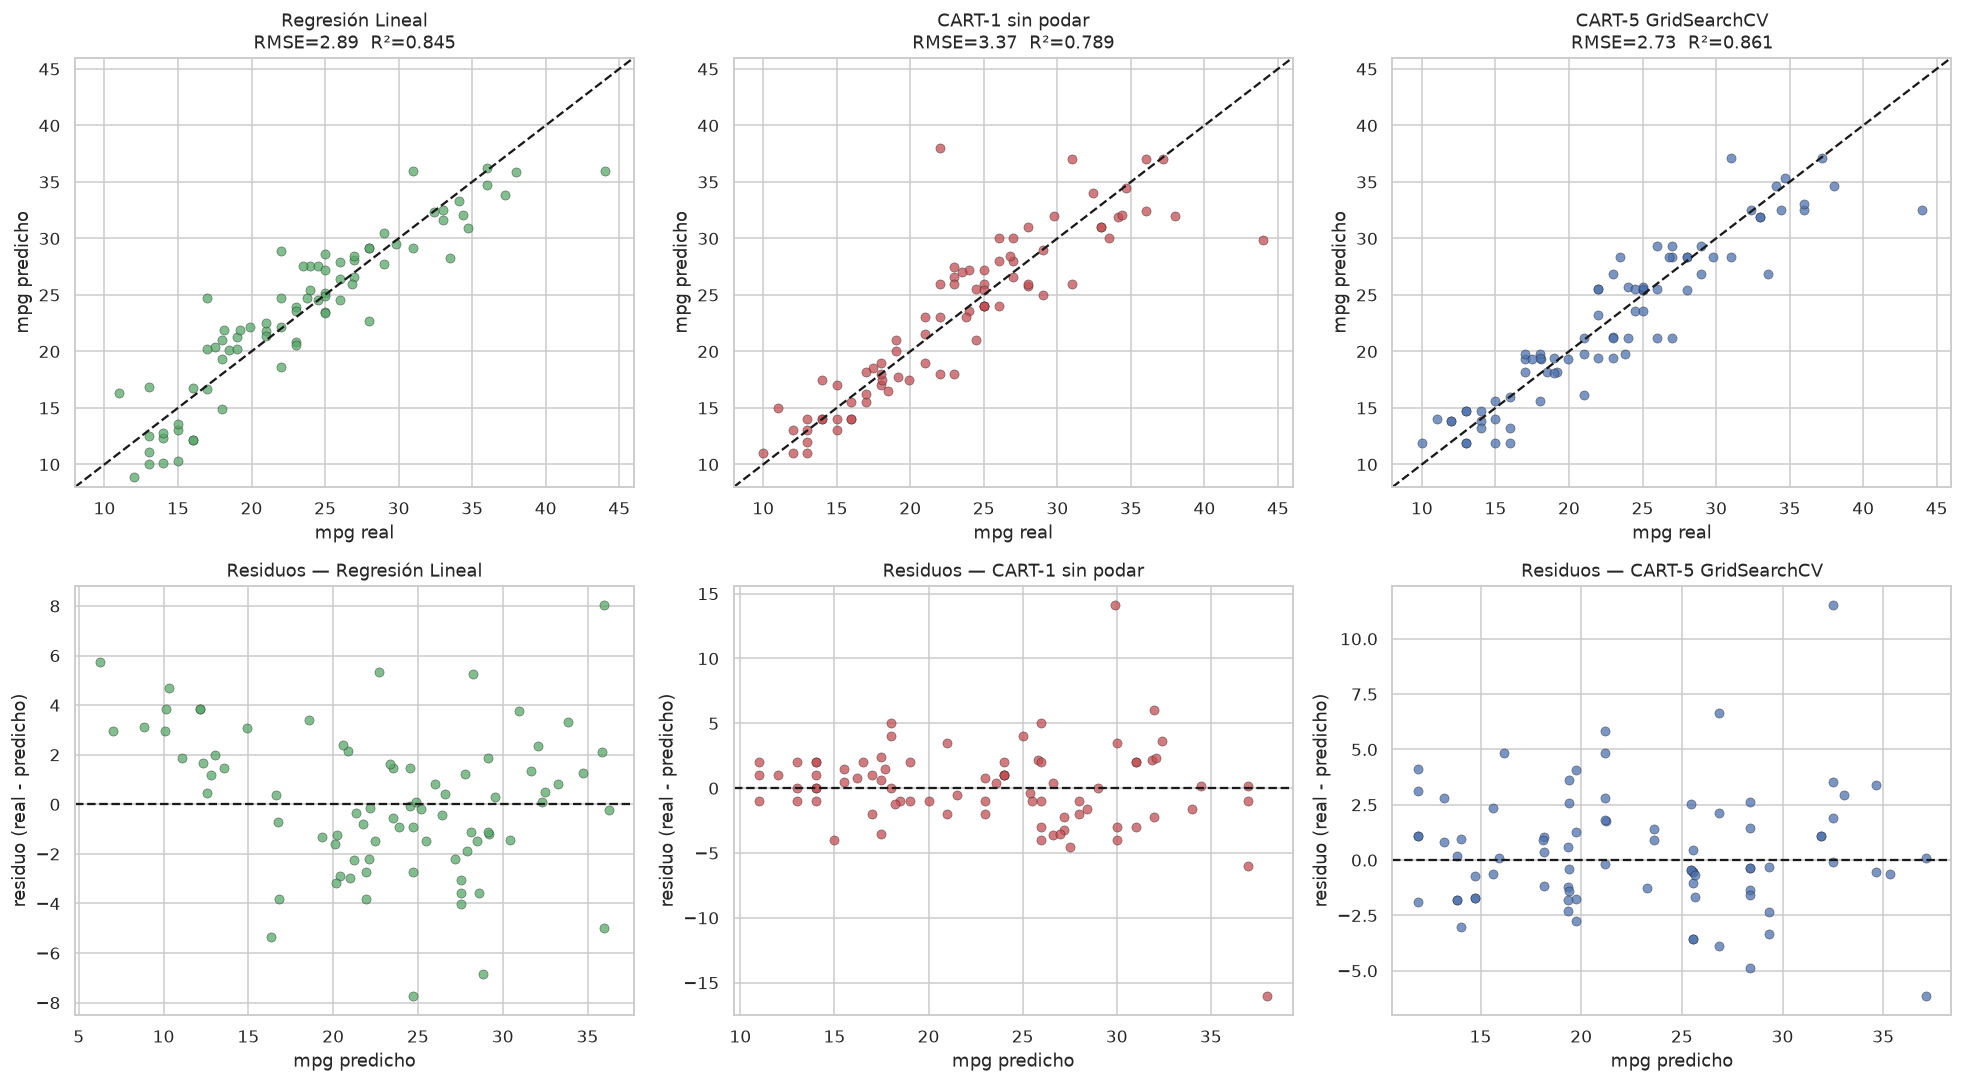

In [9]:
show = ["Regresión Lineal", "CART-1 sin podar", "CART-5 GridSearchCV"]
cols = ["#55A868", "#C44E52", "#4C72B0"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
lims = [y_test.min() - 2, y_test.max() + 2]
for j, (name, col) in enumerate(zip(show, cols)):
    axes[0, j].scatter(y_test, preds[name], alpha=0.75, color=col, edgecolor="k", lw=0.3)
    axes[0, j].plot(lims, lims, "k--"); axes[0, j].set_xlim(lims); axes[0, j].set_ylim(lims)
    axes[0, j].set_title(f"{name}\nRMSE={results.loc[name,'RMSE test']:.2f}  R²={results.loc[name,'R² test']:.3f}")
    axes[0, j].set_xlabel("mpg real"); axes[0, j].set_ylabel("mpg predicho")
    res = y_test - preds[name]
    axes[1, j].scatter(preds[name], res, alpha=0.75, color=col, edgecolor="k", lw=0.3)
    axes[1, j].axhline(0, color="k", ls="--"); axes[1, j].set_title(f"Residuos — {name}")
    axes[1, j].set_xlabel("mpg predicho"); axes[1, j].set_ylabel("residuo (real - predicho)")
plt.tight_layout(); savefig("item2_real_vs_pred"); plt.show()

_(análisis pendiente)_

## 5. Curva de complejidad (diagnóstico sesgo-varianza)

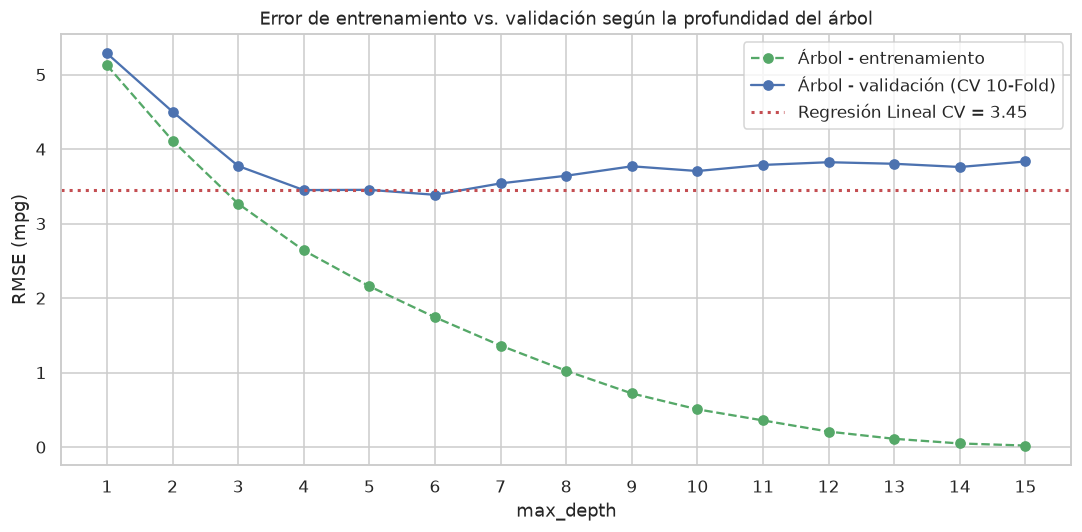

Profundidad con menor RMSE CV: 6 -> 3.386


In [10]:
depths = list(range(1, 16))
tr, va = [], []
for d in depths:
    s = cross_validate(tree(max_depth=d), X_train, y_train, cv=kf, n_jobs=-1,
                       scoring="neg_root_mean_squared_error", return_train_score=True)
    tr.append(-s["train_score"].mean()); va.append(-s["test_score"].mean())
lr_cv = results.loc["Regresión Lineal", "RMSE CV (media)"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(depths, tr, "--o", color="#55A868", label="Árbol - entrenamiento")
ax.plot(depths, va, "-o", color="#4C72B0", label="Árbol - validación (CV 10-Fold)")
ax.axhline(lr_cv, color="#C44E52", ls=":", lw=2, label=f"Regresión Lineal CV = {lr_cv:.2f}")
ax.set_xlabel("max_depth"); ax.set_ylabel("RMSE (mpg)"); ax.set_xticks(depths)
ax.set_title("Error de entrenamiento vs. validación según la profundidad del árbol"); ax.legend()
plt.tight_layout(); savefig("item2_complejidad"); plt.show()
print("Profundidad con menor RMSE CV:", depths[int(np.argmin(va))], "->", round(min(va), 3))

_(análisis pendiente)_

## 6. Naturaleza de las predicciones: función escalonada vs. recta (variable `weight`)

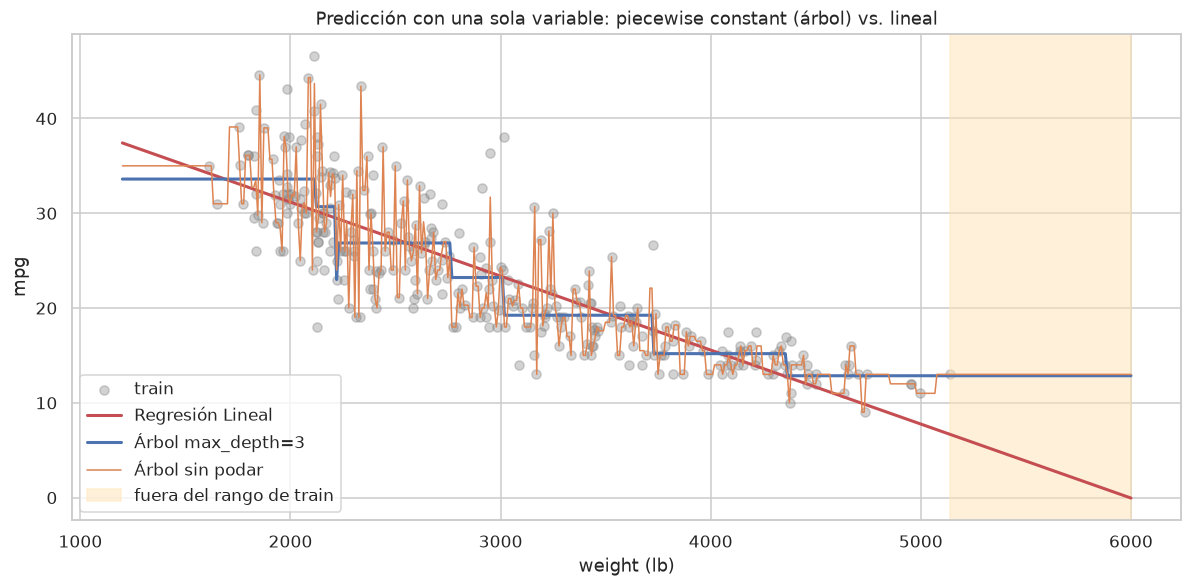

In [11]:
Xw_tr = X_train[["weight"]]; grid_w = pd.DataFrame({"weight": np.linspace(1200, 6000, 500)})
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(X_train["weight"], y_train, alpha=0.35, color="gray", label="train")
for lbl, m, col in [("Regresión Lineal", LinearRegression(), "#C44E52"),
                    ("Árbol max_depth=3", DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE), "#4C72B0"),
                    ("Árbol sin podar", DecisionTreeRegressor(random_state=RANDOM_STATE), "#DD8452")]:
    m.fit(Xw_tr, y_train)
    ax.plot(grid_w["weight"], m.predict(grid_w), color=col, lw=2 if "podar" not in lbl else 1, label=lbl)
ax.axvspan(X_train["weight"].max(), 6000, color="#FFE4B5", alpha=0.5, label="fuera del rango de train")
ax.set_xlabel("weight (lb)"); ax.set_ylabel("mpg"); ax.legend()
ax.set_title("Predicción con una sola variable: piecewise constant (árbol) vs. lineal")
plt.tight_layout(); savefig("item2_escalonado"); plt.show()

_(análisis pendiente)_

## 7. Interpretabilidad: árbol de profundidad 3 e importancia de variables

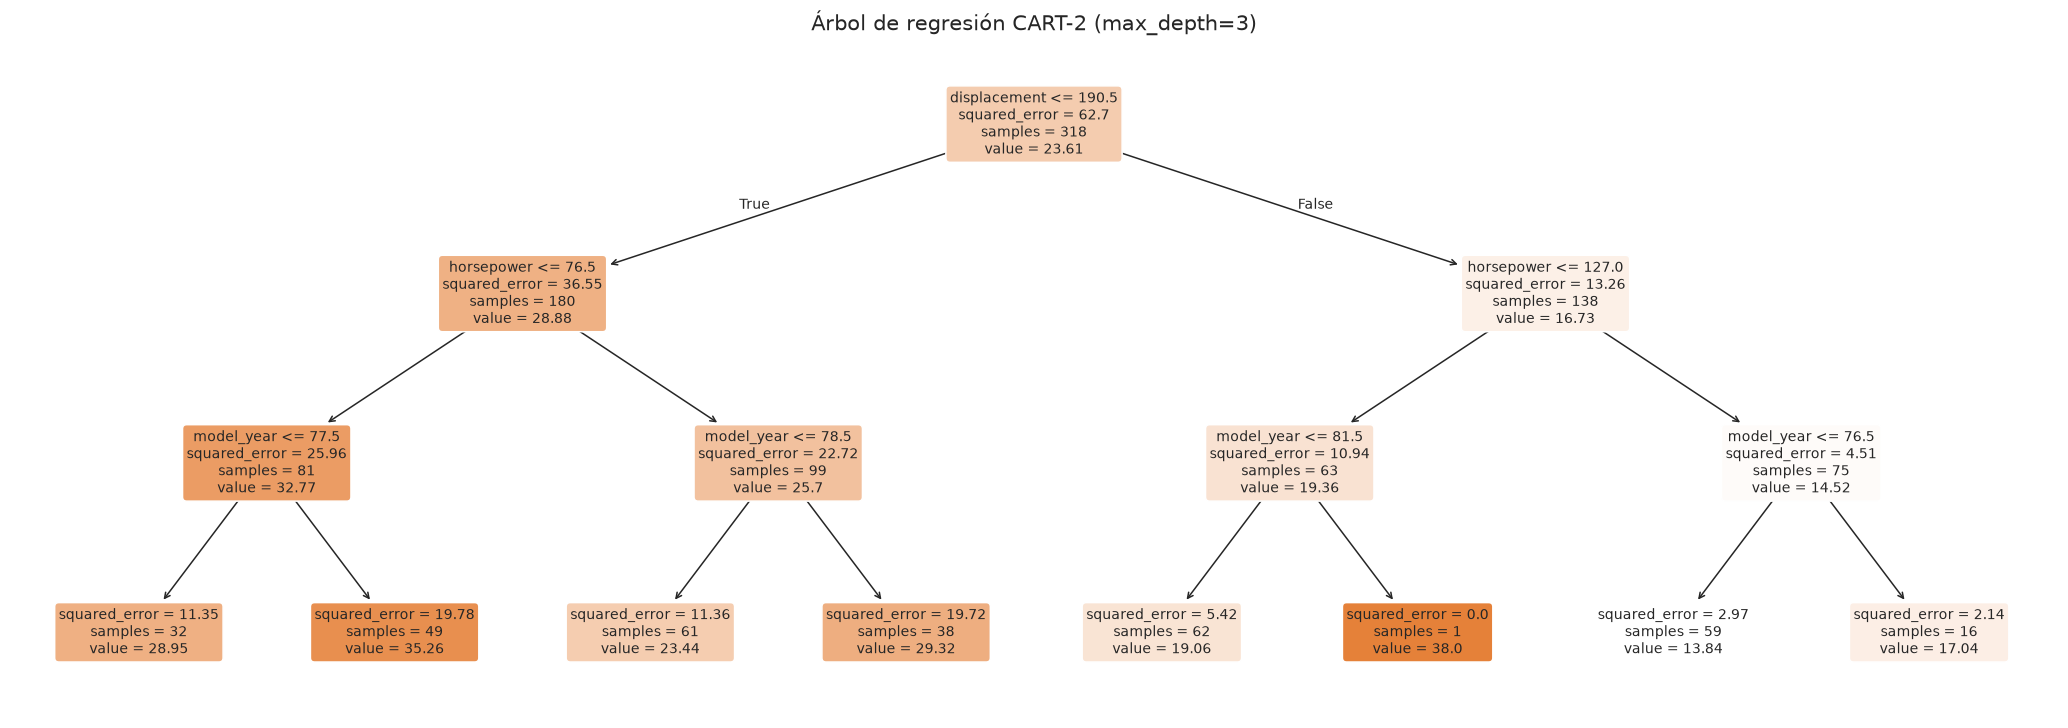

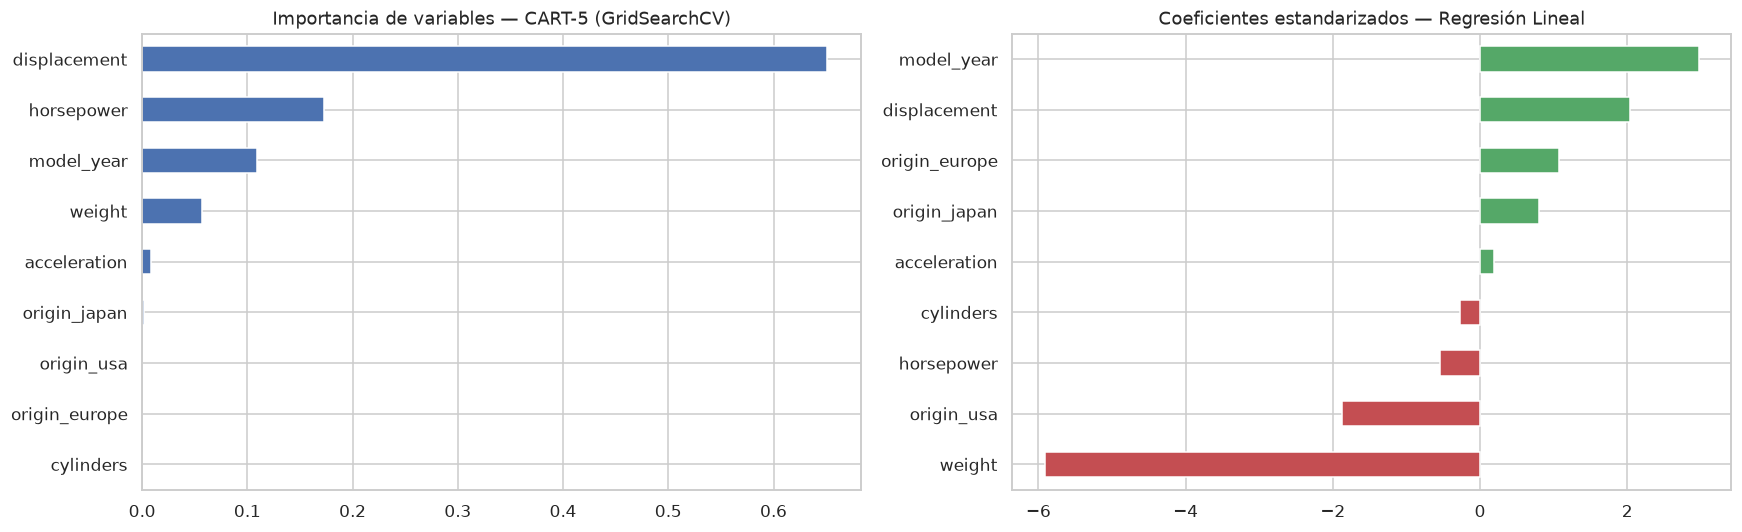

In [12]:
from sklearn.tree import plot_tree

feat_names = features_num + [f"origin_{c}" for c in
                             models["CART-2 max_depth=3"].named_steps["prep"]
                             .named_transformers_["cat"].categories_[0]]
fig, ax = plt.subplots(figsize=(24, 8))
plot_tree(models["CART-2 max_depth=3"].named_steps["model"], feature_names=feat_names, filled=True,
          rounded=True, fontsize=9, ax=ax, precision=2)
ax.set_title("Árbol de regresión CART-2 (max_depth=3)", fontsize=14)
savefig("item2_arbol"); plt.show()

imp = pd.Series(models["CART-5 GridSearchCV"].named_steps["model"].feature_importances_, index=feat_names)
coef = pd.Series(models["Regresión Lineal"].named_steps["model"].coef_, index=feat_names)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
imp.sort_values().plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Importancia de variables — CART-5 (GridSearchCV)")
coef.sort_values().plot(kind="barh", ax=axes[1],
                        color=["#C44E52" if v < 0 else "#55A868" for v in coef.sort_values()])
axes[1].set_title("Coeficientes estandarizados — Regresión Lineal")
plt.tight_layout(); savefig("item2_importancia"); plt.show()

_(análisis pendiente)_

## 8. Significancia estadística e intervalos de confianza

In [13]:
from scipy.stats import wilcoxon
from sklearn.model_selection import RepeatedKFold, cross_val_score

rkf = RepeatedKFold(n_splits=10, n_repeats=3, random_state=RANDOM_STATE)
rep = {n: -cross_val_score(models[n], X_train, y_train, cv=rkf, n_jobs=-1,
                           scoring="neg_root_mean_squared_error") for n in models}
stats_rows = []
for n in models:
    if n == "Regresión Lineal":
        continue
    p = wilcoxon(rep["Regresión Lineal"], rep[n], zero_method="zsplit").pvalue
    stats_rows.append({"Comparación": f"Regresión Lineal vs {n}",
                       "RMSE medio LR": rep["Regresión Lineal"].mean(), "RMSE medio árbol": rep[n].mean(),
                       "Diferencia (árbol - LR)": (rep[n] - rep["Regresión Lineal"]).mean(),
                       "p-valor Wilcoxon": p, "Significativo (α=0.05)": "Sí" if p < 0.05 else "No"})
stats_df = pd.DataFrame(stats_rows)
ci_df = pd.DataFrame({n: bootstrap_ci(y_test, preds[n], rmse) for n in models},
                     index=["IC95% inf", "IC95% sup"]).T
display(stats_df.round(4)); display(ci_df.round(3))

,Comparación,RMSE medio LR,RMSE medio árbol,Diferencia (árbol - LR),p-valor Wilcoxon,Significativo (α=0.05)
0,Regresión Lineal vs CART-1 sin podar,3.4631,3.8355,0.3724,0.0549,No
1,Regresión Lineal vs CART-2 max_depth=3,3.4631,3.7231,0.2600,0.0062,Sí
2,"Regresión Lineal vs CART-3 depth=5, leaf=5, sp...",3.4631,3.3169,-0.1462,0.1004,No
3,"Regresión Lineal vs CART-4 depth=4, leaf=10%",3.4631,3.7620,0.2989,0.0093,Sí
4,Regresión Lineal vs CART-5 GridSearchCV,3.4631,3.1904,-0.2726,0.0145,Sí


,IC95% inf,IC95% sup
Regresión Lineal,2.401,3.382
CART-1 sin podar,2.266,4.546
CART-2 max_depth=3,2.875,4.653
"CART-3 depth=5, leaf=5, split=10",2.108,3.400
"CART-4 depth=4, leaf=10%",2.771,3.862
CART-5 GridSearchCV,2.102,3.408


_(análisis pendiente)_

In [14]:
save_results({
    "results": results.reset_index().to_dict(orient="records"),
    "best_params": best_params, "grid_best_rmse_cv": -grid.best_score_,
    "stats": stats_df.to_dict(orient="records"),
    "ci": ci_df.reset_index().rename(columns={"index": "Modelo"}).to_dict(orient="records"),
    "complexity": {"depths": depths, "train": tr, "cv": va},
}, "item2")
print("Resultados guardados en results/item2.json")

Resultados guardados en results/item2.json


## Conclusiones
_(pendiente)_